# Законы распределения дискретных случайных величин

---

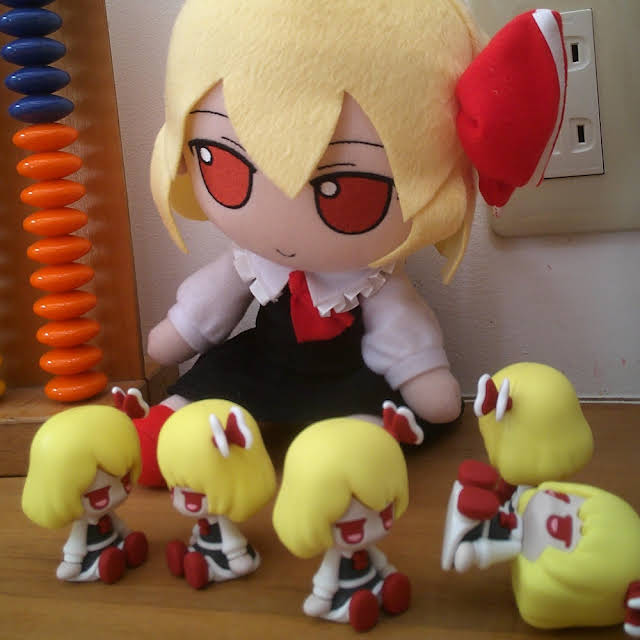

In [6]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binom, poisson, geom, hypergeom, mode

In [29]:
def law_table(dist, X):
    return pd.DataFrame(data=dist.pmf(X).reshape(1, -1), columns=X, index=['p'])

def mode_of(dist, X):
    p = dist.pmf(X)
    return X[np.isclose(p, p.max())]

def characteristics(dist, X):
    print(f'Мат. ожидание M(X) = {dist.mean():.4f}')
    print(f'Дисперсия D(X)     = {dist.var():.4f}')
    print(f'Ср. кв. отклонение = {dist.std():.4f}')
    print(f'Мода Mo(X)         = {", ".join(str(m) for m in mode_of(dist, X))}')

def polygon(dist, X, title):
    p = dist.pmf(X)
    plt.figure(figsize=(8, 4))
    plt.plot(X, p, 'o-', color='tab:blue')
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.show()

## a) Биномиальное распределение

### Условие
Служба доставки отправила 15 посылок. Каждая посылка независимо от остальных повреждается в пути с вероятностью 0,12. Случайная величина $X$ - число повреждённых посылок среди 15.

$$P(X=m) = C_n^m \, p^m (1-p)^{n-m}, \quad m = 0, 1, \dots, n$$

$$M(X) = np, \qquad D(X) = npq$$

In [30]:
n = 15
p = 0.12

dist = binom(n, p)
X = np.arange(0, n + 1)

law_table(dist, X)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
p,0.146974,0.300628,0.286963,0.169569,0.069369,0.020811,0.00473,0.000829,0.000113,0.000012,9.812534e-07,6.082149e-08,2.764613e-09,8.699832e-11,1.694772e-12,1.540702e-14


Мат. ожидание M(X) = 2.1600
Дисперсия D(X)     = 1.0944
Ср. кв. отклонение = 1.0461
Мода Mo(X)         = 2


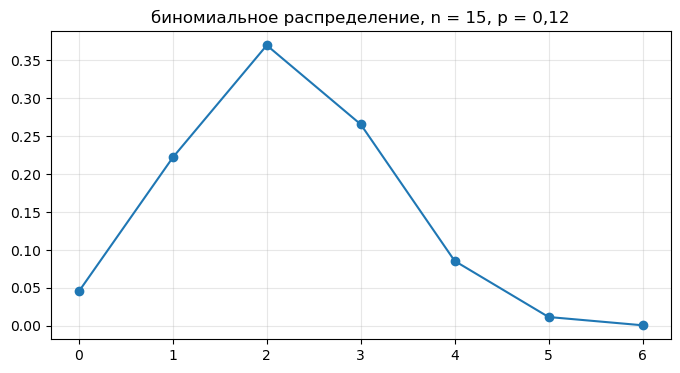

In [46]:
characteristics(dist, X)

polygon(dist, X, 'биномиальное распределение, n = 15, p = 0,12')

## b) Распределение Пуассона

### Условие 
В типографии печатают тираж 1400 книг. Вероятность того, что отдельная книга будет бракованной, равна 0,0025 (брак независим). Случайная величина $X$ - число бракованных книг в тираже. Так как $n$ велико, а $p$ мало, $X$ распределена по закону Пуассона с $\lambda = np$.

$$P(X=m) = \frac{\lambda^m}{m!}\, e^{-\lambda}, \quad m = 0, 1, 2, \dots$$

$$M(X) = \lambda, \qquad D(X) = \lambda$$

In [32]:
n, p = 1400, 0.0025
lam = n * p
m = 12

dist = poisson(lam)
X = np.arange(0, m + 1)

law_table(dist, X)

,0,1,2,3,4,5,6,7,8,9,10,11,12
p,0.030197,0.105691,0.184959,0.215785,0.188812,0.132169,0.077098,0.038549,0.016865,0.006559,0.002296,0.00073,0.000213


Мат. ожидание M(X) = 3.5000
Дисперсия D(X)     = 3.5000
Ср. кв. отклонение = 1.8708
Мода Mo(X)         = 3


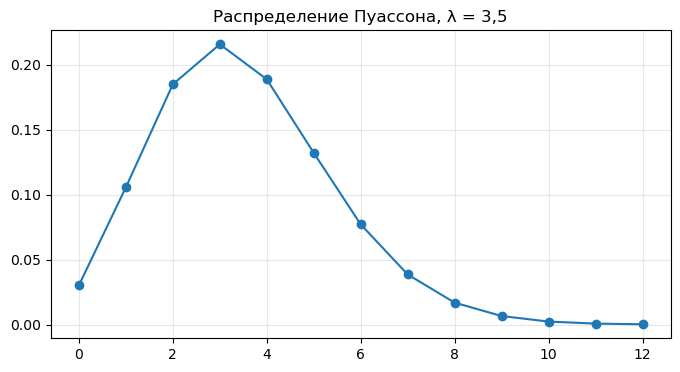

In [33]:
characteristics(dist, X)

polygon(dist, X, 'Распределение Пуассона, λ = 3,5')

## c) Геометрическое распределение

### Условие
Контролёр проверяет изделия на конвейере по одному до тех пор, пока не обнаружит первое бракованное. Вероятность того, что случайное изделие бракованное, равна 0,08. Случайная величина $X$ — номер проверенного изделия, на котором обнаружен первый брак.

$$P(X=k) = (1-p)^{k-1}\, p, \quad k = 1, 2, 3, \dots$$

$$M(X) = \frac{1}{p}, \qquad D(X) = \frac{1-p}{p^2}$$

In [41]:
p = 0.08
k = 15

dist = geom(p)
X = np.arange(1, k + 1)

law_table(dist, X)

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
p,0.08,0.0736,0.067712,0.062295,0.057311,0.052727,0.048508,0.044628,0.041058,0.037773,0.034751,0.031971,0.029413,0.02706,0.024895


Мат. ожидание M(X) = 12.5000
Дисперсия D(X)     = 143.7500
Ср. кв. отклонение = 11.9896
Мода Mo(X)         = 1


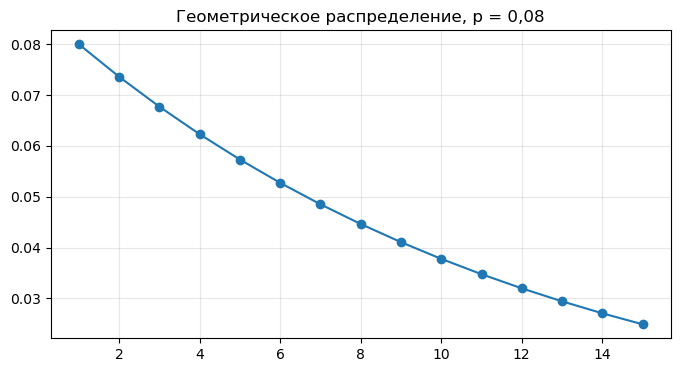

In [42]:
characteristics(dist, X)

polygon(dist, X, 'Геометрическое распределение, p = 0,08')

## d) Гипергеометрическое распределение

### Условие
В коробке 25 деталей, из них 9 окрашены в красный цвет. Наугад без возвращения берут 6 деталей. Случайная величина $X$ — число красных деталей среди отобранных.

$$P(X=m) = \frac{C_M^m \, C_{N-M}^{\,n-m}}{C_N^n}, \quad \max(0,\, n-(N-M)) \le m \le \min(n, M)$$

$$M(X) = n\,\frac{M}{N}, \qquad D(X) = n\,\frac{M}{N}\Bigl(1-\frac{M}{N}\Bigr)\frac{N-n}{N-1}$$

In [43]:
N = 25
M = 9
n = 6

dist = hypergeom(N, M, n)   # (всего, особых, выборка)
X = np.arange(max(0, n - (N - M)), min(n, M) + 1)

law_table(dist, X)

,0,1,2,3,4,5,6
p,0.045217,0.221976,0.36996,0.265613,0.085375,0.011383,0.000474


Мат. ожидание M(X) = 2.1600
Дисперсия D(X)     = 1.0944
Ср. кв. отклонение = 1.0461
Мода Mo(X)         = 2


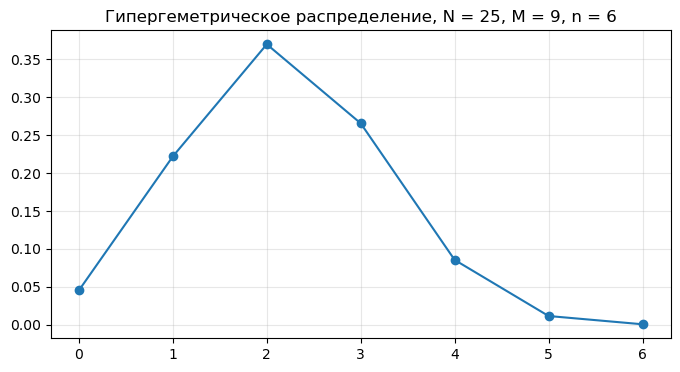

In [45]:
characteristics(dist, X)

polygon(dist, X, 'Гипергеметрическое распределение, N = 25, M = 9, n = 6')